### 0. Adjustment of project

In [1]:
import meep as mp
import torch
from configs import conf_test as conf
from lib import numpy_functions as nf
from lib import core_finctions as cf
from lib import my_gui, my_decoders, my_sources
from lib import help_functions
from autograd import numpy as npa
import numpy as np
mp.verbosity(0)

1

In [4]:
"""
objective function
"""

def J(FF):
    """
    FF: an array of shapes (n_points, n_waves, n_fields). 
    penalty_coef: penalty coefficient (selected empirically).
    """
    # calculate the point‑by-point intensity: shape = (n_points, n_waves)
    I = npa.abs(FF[0, :, 2])**2 / angIPlane_base_mean[global_index_angle] / angIAiry_norm_max[global_index_angle]

    # the basic goal is the wave average
    J_base = npa.mean(I)
    
    # penalty for the spread between waves (variance or std^2)
    penalty = penalty_coef * (npa.std(I))**2 
    print(f"penalty: {penalty}")

    return J_base - penalty

class OptFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, *x_tensors):

        # Forward pass for both single- and multi-frequency optimization.
        # Unwraps torch tensors to numpy arrays, calls external opt(), and saves gradients.

        rho_list = []
        shapes = []
        # Extract data and shapes
        for x in x_tensors:
            arr = x.detach().cpu().numpy()
            # if extra leading dim, squeeze it
            if arr.ndim > 1 and arr.shape[0] == 1:
                arr = arr.squeeze(0)
            shapes.append(arr.shape)
            rho_list.append(arr.flatten())

        # Call external optimizer: returns objective and gradients
        f0, grad_rho = opt(rho_list)

        # Save context for backward
        ctx.grad_rho = grad_rho
        ctx.shapes = shapes
        ctx.device = x_tensors[0].device
        ctx.dtype = x_tensors[0].dtype
        
        # print(f"shapes len = {len(shapes)}")
        # print("shapes:", ctx.shapes)
        # print("returned grad shapes:", [g.shape for g in ctx.grad_rho])
        missing = set(range(len(ctx.shapes))) - set(range(len(ctx.grad_rho)))
        print("Missing gradient indices:", missing)

        # Return scalar objective as torch tensor
        return torch.as_tensor(f0, device=ctx.device, dtype=ctx.dtype)

    @staticmethod
    def backward(ctx, grad_output):
        # Backward pass: reshape and convert numpy gradients to torch,
        # handling both single- and multi-frequency cases.

        grads = []
        for g_np, shape in zip(ctx.grad_rho, ctx.shapes):
            # For multi-frequency, collapse along freq axis
            if g_np.ndim == 2:
                # average gradients over frequencies
                g_arr = np.mean(g_np, axis=1).reshape(shape)
            else:
                # single-frequency gradient
                g_arr = np.asarray(g_np, dtype=np.float64).reshape(shape)

            # Convert to torch tensor and scale by upstream grad_output
            g_torch = torch.from_numpy(g_arr).to(device=ctx.device, dtype=ctx.dtype)
            grads.append(g_torch * grad_output)
    
        # Add zeros for "lost" inputs
        n_missing = len(ctx.shapes) - len(grads)
        if n_missing > 0:
            for idx in range(n_missing):
                shape = ctx.shapes[len(grads) + idx]
                zero = torch.zeros(shape, device=ctx.device, dtype=ctx.dtype)
                grads.append(zero)
            
        # Return gradient for each input
        return tuple(grads)

def opt_torch(*x_tensors):
    # Apply the OptFunction in a torch-friendly way.
    return OptFunction.apply(*x_tensors)

## Main program
### 1.1 Normalization and comparison calculations

In [3]:
"""
Base parameters
"""
# 1. Shape
global_index_angle = None

a_initial_params = 1.0
h_initial_params = 0.6 # For 1 param optimization mode adj cell height
rt_np_global = nf.calculate_radii_step(D=conf.aperture, orders=conf.orders)

global_a_params = torch.full((conf.orders,), a_initial_params, dtype=torch.float64)
global_h_params = torch.full((conf.orders,), h_initial_params, dtype=torch.float64)

angle_in_rad = np.radians(conf.angle_list)
angle_in_deg = conf.angle_list
angle_after_refraction_in_radii = my_sources.refraction_input(angle_in_deg, conf.in_epsilon)
angle_after_refraction_in_deg = np.rad2deg(angle_after_refraction_in_radii)

# 2. Sources
    # A complete set of sources for all n_angels corners.
    # src is the only plane wave with one long wave
    # batch is a group of continuous plane waves with different wavelengths at the same angle
    # stack is a group with different wave angles of a group of waves with different wavelengths
    
stack_batch_src = []
for angle in angle_after_refraction_in_radii:
    src = my_sources.BatchEigenmodeSource(
        frequencies=conf.inc_frequents_array,
        df = conf.inc_df,
        resolution=conf.sim_resolution,
        diaphragm=conf.diaphragm,
        center=mp.Vector3(x=conf.main_source_center.x, y = 0 ),
        angle_in_rad=angle,
        epsilon=conf.in_epsilon,
        verbose=False,
    )
    batch_src = src.get_sources()
    stack_batch_src.append(batch_src)


# 3 Initializing the parameters
p_min, p_max = 0.01, 100.0
h_min, h_max = 0.01, conf.at_hei

    #start the decoders for the reverse transition to [p_min, p_max] and [h_min, h_max]
decoder_a = my_decoders.SigmoidDecoder(pmin=p_min, pmax=p_max)
decoder_h = my_decoders.SigmoidDecoder(pmin=h_min, pmax=h_max)

# 4. Local monitor
locNearRegion = mp.Near2FarRegion(center=conf.flux_center, size=mp.Vector3(x = 0, y=conf.loc_cell.y)) # monitor

# 5. GUI output
panel = my_gui.LiveInfoPanel()
panel.show()

# 6. Save and load
# "name" if you load, None if you save

"""
Examples

filename_focus_IAiry = "focusAiry_D500.0_f500.0_diaph500_res5_nfreq3.npy"
filename_base_IAiry = "baseAiry_D500.0_f500.0_diaph500_res5_nfreq3.npy"
file_name_IBase = "basePlane_D500.0_f500.0_diaph500_res5_nfreq3.npy"

filename_focus_IAiry = None
filename_base_IAiry = None
file_name_IBase = None
"""

# filename_focus_IAiry = None
# filename_base_IAiry = None
# file_name_IBase = None

filename_focus_IAiry = "focusAiry_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy"
filename_base_IAiry = "baseAiry_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy"
file_name_IBase = "basePlane_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy"

# filename_focus_IAiry = "focusAiry_D15000.0_f5000.0_diaph5000_res4_nfreq3.npy"
# filename_base_IAiry = "baseAiry_D15000.0_f5000.0_diaph5000_res4_nfreq3.npy"
# file_name_IBase = "basePlane_D15000.0_f5000.0_diaph5000_res4_nfreq3.npy"

# filename_focus_IAiry = "focusAiry_D18000.0_f6000.0_diaph6000_res4_nfreq3.npy"
# filename_base_IAiry = "baseAiry_D18000.0_f6000.0_diaph6000_res4_nfreq3.npy"
# file_name_IBase = "basePlane_D18000.0_f6000.0_diaph6000_res4_nfreq3.npy"


HTML(value='\n        \n        <style>\n            .live-panel { \n                border: 2px solid #4CAF50…

Data from focusAiry_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy loaded successfully.
Data from baseAiry_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy loaded successfully.


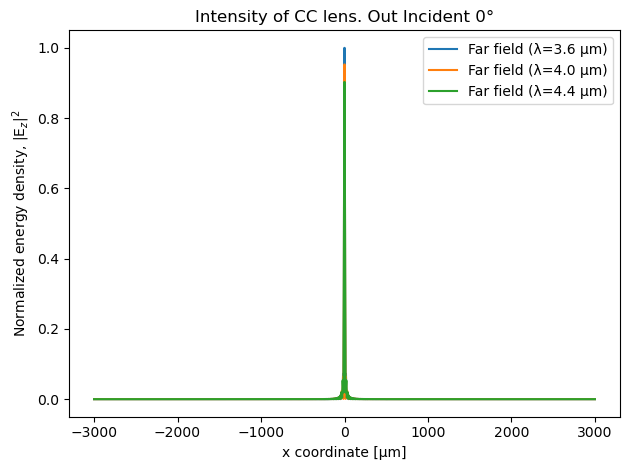

i=0, angle_deg=0, max_IAiry_norm=[403.76377666 384.72661019 364.57882101]
Data from basePlane_D6000.0_f2000.0_diaph2000_res5_nfreq3.npy loaded successfully.


In [11]:
"""
Normalization
"""
angIAiry_norm_max = []

# AIRY wave
IAiry, IAiry_base, sim = nf.get_IAiry_simulation(
    monitor =  locNearRegion,
    cell = conf.loc_cell,
    filename_focus_airy = filename_focus_IAiry,
    filename_base_airy= filename_base_IAiry,
    resolution = conf.sim_resolution,
    epsilon = 1,
    get_base=True,
    symmetries=[mp.Mirror(mp.Y)]
)
IAiry_norm = IAiry/IAiry_base
IAiry_norm_max = IAiry_norm.max(axis=0)
abscissa = nf.get_abscissa(conf.spot_ff, IAiry_norm, 0, 0)
nf.plot_intensity(
    IAiry_norm/IAiry_norm.max(),
    out_angle_in_deg=0,
    wavelength_array=conf.inc_wavelength_array,
    abscissa=abscissa,
    isfwhm=False,
)
for i, (angle_rad, angle_deg) in enumerate(zip(angle_in_rad, angle_in_deg)):
    # abscissa = nf.get_abscissa(conf.spot_ff, IAiry/IAiry.max(axis = 0), angle_in_deg[i], i * conf.diaphragm)
    angIAiry_norm_max.append(IAiry_norm_max*np.cos(angle_rad))
    print(f"i={i}, angle_deg={angle_deg}, max_IAiry_norm={angIAiry_norm_max[i]}")

# IBase for normalization
angIPlane_base = nf.get_Ibase_batch_simulation(
    monitor =  locNearRegion,
    sources_batch=stack_batch_src,
    cell=conf.loc_cell,
    frequents_array=conf.inc_frequents_array,
    filename= file_name_IBase,
    symmetries = [mp.Mirror(mp.Y)],
    verbose = True,
)
angIPlane_base_mean = np.mean(angIPlane_base, axis=1)  

### 1.2 Optimizer

In [9]:
# ____ Multi-angels _____
opt_zone_start = 0
opt_zone_end = conf.n_angles
loc_symmetry = None # symmetry - off - faster simulation
is_center=None
lr = None
beta = None
num_steps = 40  # number of epochs

# opt_zone_end = 1
for i in range(opt_zone_start, opt_zone_end):
    global_index_angle = i
    if angle_in_deg[i] == 0:
        is_center=True
        penalty_coef = 20.0
        lr = 0.6
        beta = 3.0
    elif angle_in_deg[i] > 0 and angle_in_deg[i] < 20:
        is_center=False
        penalty_coef = 0.05
        lr = 0.5
        beta = 3.0
    elif angle_in_deg[i] > 20:
        is_center=False
        # penalty_coef = 0.02
        penalty_coef = 0.001
        lr = 1.0
        beta = 3.0

    loc_orders = nf.get_loc_orders(conf.diaphragm_orders, is_center)
    loc_rt_np = rt_np_global[:loc_orders]
    loc_drt_np, loc_midrt_np = nf.get_drt_midrt(rt_np_global, orders=loc_orders, is_center=is_center)
    resolutions = nf.AdaptiveResolution(
        drt=loc_drt_np,
        x_dim=conf.x_dim,
        h_dim= conf.h_dim,
    ).generate()

    # 0.0) Extract local params
    loc_a_params = cf.get_local_tensor_from_global(global_a_params, i, loc_orders)
    loc_h_params = cf.get_local_tensor_from_global(global_h_params, i, loc_orders)
    # 0.1) Initializing the optimizer
    opt = cf.init_opt(i, J, NearRegion=locNearRegion,stack_batch_src=stack_batch_src, resolutions = resolutions, a_initial=loc_a_params, h_initial=loc_h_params, rt_np = loc_rt_np, drt_np = loc_drt_np, midrt_np = loc_midrt_np, is_center = is_center, symmetry = loc_symmetry, is_plot = False, is_plot_cross=False)
    # 0.2) Initial hyper params
    loc_optimizer, scheduler, store_loc_history, loc_u_a, loc_u_h = cf.init_loc_opt_hyper(a_initial=loc_a_params, h_initial=loc_h_params, p_min=p_min, p_max=p_max, h_min=h_min, h_max=h_max, lr=lr, regime=1)
    # 1) Begin optimization loop
    loc_history, loc_best_a_params, loc_best_h_params  = cf.run_loc_opt(opt_torch, loc_rt_np, loc_drt_np , loc_optimizer,scheduler, loc_u_a, loc_u_h, store_loc_history, beta, num_steps, decoder_a, decoder_h, resolutions, regime=1)    
    # 2) Update global_params
    cf.update_global_params(i, global_a_params, global_h_params, loc_best_a_params, loc_best_h_params, is_save = True)
    # 3) Save history
    help_functions.save_history(loc_history, save=True, index=global_index_angle)
    # 4) Visualise
    cf.viz_loc_opt(loc_history, loc_best_a_params,loc_best_h_params, save_path=f"opt_progress_and_param{i}.pdf", save_format="pdf")

Starting forward run...


KeyboardInterrupt: 

In [ ]:
# # ____ Single-angel _____
# loc_symmetry = None
# is_center=None
# lr = None
# beta = None
# num_steps = 40  # number of epochs
# 
# i = 1
# global_index_angle = i
# if angle_in_deg[i] == 0:
#     is_center=True
#     penalty_coef = 10.0
#     lr = 0.5
#     beta = 3.0
# elif angle_in_deg[i] > 0 and angle_in_deg[i] < 20:
#     is_center=False
#     penalty_coef = 0.0
#     lr = 0.3
#     beta = 3.0
# elif angle_in_deg[i] > 20:
#     is_center=False
#     penalty_coef = 0.0
#     lr = 0.3
#     beta = 3.0
# 
# loc_orders = nf.get_loc_orders(conf.diaphragm_orders, is_center)
# loc_rt_np = rt_np_global[:loc_orders]
# loc_drt_np, loc_midrt_np = nf.get_drt_midrt(rt_np_global, orders=loc_orders, is_center=is_center)
# resolutions = nf.AdaptiveResolution(
#     drt=loc_drt_np,
#     x_dim=conf.x_dim,
#     h_dim= conf.h_dim,
# ).generate()
# 
# # 0.0) Extract local params
# loc_a_params = cf.get_local_tensor_from_global(global_a_params, i, loc_orders)
# loc_h_params = cf.get_local_tensor_from_global(global_h_params, i, loc_orders)
# # 0.1) Initializing the optimizer
# opt = cf.init_opt(i, J, NearRegion=locNearRegion,stack_batch_src=stack_batch_src, resolutions = resolutions, a_initial=loc_a_params, h_initial=loc_h_params, rt_np = loc_rt_np, drt_np = loc_drt_np, midrt_np = loc_midrt_np, is_center = is_center, symmetry = loc_symmetry, is_plot = True, is_plot_cross=False)
# # 0.2) Initial hyper params
# loc_optimizer, scheduler, store_loc_history, loc_u_a, loc_u_h = cf.init_loc_opt_hyper(i, loc_orders, a_initial=loc_a_params, h_initial=loc_h_params, p_min=p_min, p_max=p_max, h_min=h_min, h_max=h_max, lr=lr, regime=1)
# # 1) Begin optimization loop
# loc_history, loc_best_a_params, loc_best_h_params  = cf.run_loc_opt(opt_torch, loc_rt_np, loc_drt_np , loc_optimizer,scheduler, loc_u_a, loc_u_h, store_loc_history, beta, num_steps, decoder_a, decoder_h, resolutions, regime=1)    
# # 2) Update global_params
# cf.update_global_params(i, global_a_params, global_h_params, loc_best_a_params, loc_best_h_params, is_save = True)
# # 3) Save history
# help_functions.save_history(loc_history, save=True, index=global_index_angle)
# # 4) Visualise
# cf.viz_loc_opt(loc_history, loc_best_a_params,loc_best_h_params, save_path=f"opt_progress_and_param{i}.pdf", save_format="pdf")

### 1.3. TEST

In [ ]:
# global_a_params = torch.load("global_a_params_496.pt", weights_only=True)
# global_h_params = torch.load("global_h_params_496.pt", weights_only=True)

In [ ]:
# # ____ Single-angle ____
# i = 1
# if i == 0:
#     is_center=True
#     loc_symmetry = None
# else:
#     is_center=False
#     loc_symmetry = None
# 
# loc_orders = nf.get_loc_orders(conf.diaphragm_orders, is_center)
# loc_rt_np = rt_np_global[:loc_orders]
# loc_drt_np, loc_midrt_np = nf.get_drt_midrt(rt_np_global, orders=loc_orders, is_center=is_center)
# resolutions = nf.AdaptiveResolution(
#     drt=loc_drt_np,
#     x_dim=conf.x_dim,
#     h_dim= conf.h_dim,
# ).generate()
# 
# test_loc_a = cf.get_local_tensor_from_global(global_a_params, i, loc_orders)
# test_loc_h = cf.get_local_tensor_from_global(global_h_params, i, loc_orders)
# print(f"test region: {i} || angle: {angle_in_deg[i]} || include elements: {len(test_loc_a)}")
# res_axial_I, res_deep_I = cf.test_loc(
#     stack_batch_src[i],
#     rt_np = loc_rt_np, drt_np=loc_drt_np, midrt_np=loc_midrt_np,
#     resolutions=resolutions,
#     is_center = is_center,
#     loc_symmetry=loc_symmetry,
#     locNearRegion=locNearRegion,
#     best_a_params=test_loc_a,
#     best_h_params=test_loc_h,
#     cut_shift = 0.0,
#     is_plot_sim = True,
#     is_plot_cross = True,
# )
# # ASSUMING DATA
# # res_plane_I_norm = res_plane_I / res_plane_I.max(axis=0)
# # res_deep_I_norm = res_deep_I / res_deep_I.max(axis=0)
# res_axial_I_norm = res_axial_I / res_axial_I.max()
# res_deep_I_norm = res_deep_I / res_deep_I.max()
# abscissa = nf.get_abscissa(conf.spot_ff, res_axial_I, angle_in_deg[i], i * conf.diaphragm)
# abscissa_deep = nf.get_abscissa(conf.spot_ff, res_axial_I, angle_in_deg[i], conf.f)
# 
# # Crop if needed
# # I_crop, absc_crop = help_functions.recenter_and_crop(IOptimized_scaled, abscissa, ref_index=0)
# 
# # Outputs data plane
# nf.plot_intensity(
#     res_axial_I_norm,
#     out_angle_in_deg=angle_in_deg[i],
#     wavelength_array=conf.inc_wavelength_array,
#     abscissa=abscissa,
#     isfwhm=True,
#     save_path=f"psf_plot_plane{i}.pdf",
# )
# 
# # Outputs data deep
# nf.plot_intensity(
#     res_deep_I_norm,
#     out_angle_in_deg=angle_in_deg[i],
#     wavelength_array=conf.inc_wavelength_array,
#     abscissa=abscissa_deep,
#     isfwhm=True,
#     save_path=f"psf_plot_deep{i}.pdf",
# )
# 
# nf.plot_psf(
#     conf.inc_nfreq, conf.spot_ff,
#     res_axial_I,
#     abscissa=abscissa,
#     save_path = f"psf_plot{i}.pdf", 
#     save_format="pdf",
#     colorbar_to_1=False,
# )
# 
# nf.plot_mtf(
#     conf.spot_ff, res_axial_I,
#     max_view=100,
#     in_angle_in_deg=angle_after_refraction_in_deg[i],
#     out_angle_in_deg=angle_in_deg[i],
#     dif_lim=True, 
#     smooth=True,
#     I_mtf_theory = None,
#     save_path=f"mtf_plot{i}.pdf",
#     save_format="pdf"
# )
# 
# # res_axial_I = np.expand_dims(res_axial_I, axis=1)
# 
# arr_STREHL, arr_EER_airy, arr_EER_test, arr_EER_rel = nf.get_focusing_efficiency(
#     airy_focus=IAiry, 
#     airy_base=IAiry_base, 
#     test_focus=res_axial_I,
#     test_base=angIPlane_base[i],
#     abscissa=abscissa,
#     )
# 
# print(f"arr_STREHL: {arr_STREHL}") 
# print(f"arr_EER_airy: {arr_EER_airy}") 
# print(f"arr_EER_test: {arr_EER_test}") 
# print(f"arr_EER_rel: {arr_EER_rel}")
# print(f"mean STREHL: {np.mean(arr_STREHL)} +- {np.std(arr_STREHL)}")
# print(f"mean EER_rel: {np.mean(arr_EER_rel)} +- {np.std(arr_EER_rel)}")

In [ ]:
# ____ Multi-angle ____
# GET DATA
opt_zone_start = 0
opt_zone_end = conf.n_angles
# opt_zone_end = 1
for i in range(opt_zone_start, opt_zone_end):
    if i == 0:
        is_center=True
        loc_symmetry = None
    else:
        is_center=False
        loc_symmetry = None

    loc_orders = nf.get_loc_orders(conf.diaphragm_orders, is_center)
    loc_rt_np = rt_np_global[:loc_orders]
    loc_drt_np, loc_midrt_np = nf.get_drt_midrt(rt_np_global, orders=loc_orders, is_center=is_center)
    resolutions = nf.AdaptiveResolution(
        drt=loc_drt_np,
        x_dim=conf.x_dim,
        h_dim= conf.h_dim,
    ).generate()
    
    test_loc_a = cf.get_local_tensor_from_global(global_a_params, i, loc_orders)
    test_loc_h = cf.get_local_tensor_from_global(global_h_params, i, loc_orders)
    print(f"test region: {i} || angle: {angle_in_deg[i]} || include elements: {len(test_loc_a)}")
    res_axial_I, res_deep_I = cf.test_loc(
        stack_batch_src[i],
        rt_np = loc_rt_np, drt_np=loc_drt_np, midrt_np=loc_midrt_np,
        resolutions=resolutions,
        is_center = is_center,
        loc_symmetry=loc_symmetry,
        locNearRegion=locNearRegion,
        best_a_params=test_loc_a,
        best_h_params=test_loc_h,
        cut_shift = 0.0,
        is_plot_sim = False,
        is_plot_cross = False,
    )
    
    # ASSUMING DATA
    res_axial_I_norm = res_axial_I / res_axial_I.max()
    res_deep_I_norm = res_deep_I / res_deep_I.max()
    abscissa = nf.get_abscissa(conf.spot_ff, res_axial_I, angle_in_deg[i], i * conf.diaphragm)
    abscissa_deep = nf.get_abscissa(conf.spot_ff, res_axial_I, angle_in_deg[i], conf.f)
    
    # Crop if needed
    # I_crop, absc_crop = help_functions.recenter_and_crop(IOptimized_scaled, abscissa, ref_index=0)

    # Outputs data plane
    nf.plot_intensity(
        res_axial_I_norm,
        out_angle_in_deg=angle_in_deg[i],
        wavelength_array=conf.inc_wavelength_array,
        abscissa=abscissa,
        isfwhm=True,
        save_path=f"psf_plot_plane{i}.pdf",
    )
    
    # Outputs data deep
    nf.plot_intensity(
        res_deep_I_norm,
        out_angle_in_deg=angle_in_deg[i],
        wavelength_array=conf.inc_wavelength_array,
        abscissa=abscissa_deep,
        isfwhm=True,
        save_path=f"psf_plot_deep{i}.pdf",
    )
    if i == 0:
        nf.plot_psf(
            conf.inc_nfreq, conf.spot_ff,
            res_axial_I_norm,
            abscissa=abscissa,
            save_path = f"psf_plot{i}.pdf", 
            save_format="pdf",
            colorbar_to_1=False,
        )
    
    nf.plot_mtf(
        conf.spot_ff, res_axial_I,
        max_view=100,
        in_angle_in_deg=angle_after_refraction_in_deg[i],
        out_angle_in_deg=angle_in_deg[i],
        dif_lim=True, 
        smooth=True,
        I_mtf_theory = None,
        save_path=f"mtf_plot{i}.pdf",
        save_format="pdf"
    )
    
    arr_STREHL, arr_EER_airy, arr_EER_test, arr_EER_rel = nf.get_focusing_efficiency(
        airy_focus=IAiry, 
        airy_base=IAiry_base, 
        test_focus=res_axial_I,
        test_base=angIPlane_base[0],
        abscissa=abscissa,
        )
    
    print(f"arr_STREHL: {arr_STREHL}") 
    print(f"arr_EER_airy: {arr_EER_airy}") 
    print(f"arr_EER_test: {arr_EER_test}") 
    print(f"arr_EER_rel: {arr_EER_rel}")
    print(f"mean STREHL: {np.mean(arr_STREHL)} +- {np.std(arr_STREHL)}")
    print(f"mean EER_rel: {np.mean(arr_EER_rel)} +- {np.std(arr_EER_rel)}")

In [ ]:
# # ____ Single angle rotate____
# # GET DATA
# opt_zone_start = 0
# i = opt_zone_start
# test_loc_a = cf.get_local_tensor_from_global(global_a_params, i, conf.loc_orders)
# test_loc_h = cf.get_local_tensor_from_global(global_h_params, i, conf.loc_orders)
# print(f"test region: {i} || angle: {angle_in_deg[i]} || include elements: {len(test_loc_a)}")
# res_plane_I, res_deep_I = cf.test_loc_rotate(
#     i, 
#     conf.loc_orders, 
#     stack_batch_src[i],
#     rt_np, 
#     resolutions,
#     locNearRegion, 
#     test_loc_a, 
#     test_loc_h,
#     cut_shift = -1.0,
#     is_plot_sim = True,
#     is_plot_cross = True,
# )

### 4. GDS or STL

In [ ]:
global_a_params = torch.load("global_a_params_536.pt", weights_only=True)
global_h_params = torch.load("global_h_params_536.pt", weights_only=True)

In [ ]:
"""
GDS
"""

# nf.generate_lens_gds_2params(global_a_params, global_h_params, conf.orders, rt_np_global, MIN_POLY_AREA=0.05, Q = 60, w = conf.w, filename='gds_1param_15mm_ang0_39.8_aSi_h2.gds', cell_name = 'LENS_CELL', n_layers=1)

# nf.generate_lens_gds_2params(global_a_params, global_h_params, conf.orders, rt_np_global, MIN_POLY_AREA=0.08, Q = 25, w = conf.w, filename='gds_1param_6mm_ang0_33.7_aSi_h0.6.gds', cell_name = 'LENS_CELL', n_layers=1)

# nf.generate_lens_gds_by_area(global_a_params, global_h_params, conf.orders, rt_np_global, MIN_AREA=0.08, MID_AREA = 0.5, BIG_AREA = 1.0, Q = 25, w = conf.w, filename='gds_3layers_1param_6mm_ang0_33.7_aSi_h0.6.gds', cell_name = 'LENS_CELL')

nf.generate_lens_gds_by_tail_thickness(global_a_params, global_h_params, conf.orders, rt_np_global, MIN_POLY_AREA=0.08, Q = 25, MID_FEATURE=0.250, BIG_FEATURE=0.350, w = conf.w, filename='gds_3layers_feature_1param_6mm_ang0_33.7_aSi_h0.6.gds', cell_name = 'LENS_CELL7')